# Week 1 · Exploratory Data Analysis (EDA)

This notebook asks concrete questions before modeling:

1. Is the file complete and internally consistent?
2. Were the three email groups similar before the email was sent?
3. How did visits, purchases and spending differ by randomized email assignment?
4. Do responses vary by pre-campaign customer information, especially prior email interest?

**Important:** EDA helps us understand the experiment and choose sensible modeling steps. Subgroup patterns below are exploratory; the untouched test split later checks model ranking separately.

Open the repository root in VS Code, select its `.venv` notebook kernel, and run cells from top to bottom.

In [1]:
from pathlib import Path
import hashlib
import itertools
import json

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "data/raw/hillstrom.csv").exists()), None)
if ROOT is None:
    raise FileNotFoundError("Open the project folder containing data/raw/hillstrom.csv.")
ARMS = ["No E-Mail", "Mens E-Mail", "Womens E-Mail"]
FEATURES = ["recency", "history", "mens", "womens", "newbie", "zip_code", "channel"]
(ROOT / "results").mkdir(exist_ok=True)
def save_result(name, value):
    (ROOT / "results" / name).write_text(json.dumps(value, indent=2, allow_nan=False))

# Keep the original file unchanged; all EDA begins from this copy.
source_path = ROOT / "data/raw/hillstrom.csv"
data = pd.read_csv(source_path)
print(f"Loaded {len(data):,} rows and {len(data.columns)} columns")

Loaded 64,000 rows and 12 columns


## 1. Check data quality and understand what each column means

The campaign assignment is `segment`. The `mens` and `womens` columns describe a customer's earlier shopping interest; they are **not** the email that was sent. The `visit`, `conversion`, and `spend` columns are outcomes that happen after assignment, so they must never be model input features.

In [2]:
# One row per source column: type, missing values, unique values and range.
profile = pd.DataFrame({
    "dtype": data.dtypes.astype(str),
    "missing": data.isna().sum(),
    "unique_values": data.nunique(dropna=False),
})
for column in data.select_dtypes(include="number"):
    profile.loc[column, "minimum"] = data[column].min()
    profile.loc[column, "median"] = data[column].median()
    profile.loc[column, "maximum"] = data[column].max()

print("Column profile:")
print(profile.fillna("—").to_string())
print(f"\nExact repeated rows: {data.duplicated().sum():,}")
print(f"\nTreatment group counts:\n{data.segment.value_counts().reindex(ARMS)}")

# Validate the key outcome relationships instead of silently repairing them.
print("\nOutcome consistency checks:")
print("Purchases without a visit:", int(((data.conversion == 1) & (data.visit == 0)).sum()))
print("Positive spending without a purchase:", int(((data.spend > 0) & (data.conversion == 0)).sum()))
print("Purchases with zero spending:", int(((data.conversion == 1) & (data.spend == 0)).sum()))

print("\nBaseline feature meanings:")
print("recency = months since last purchase; history = earlier spending in dollars")
print("mens / womens = prior shopping interests; newbie = first-time customer flag")
print("segment = randomized email assignment; visit / conversion / spend = outcomes")

Column profile:
                   dtype  missing  unique_values minimum  median  maximum
recency            int64        0             12     1.0     6.0     12.0
history_segment      str        0              7       —       —        —
history          float64        0          34833   29.99  158.11  3345.93
mens               int64        0              2     0.0     1.0      1.0
womens             int64        0              2     0.0     1.0      1.0
zip_code             str        0              3       —       —        —
newbie             int64        0              2     0.0     1.0      1.0
channel              str        0              3       —       —        —
segment              str        0              3       —       —        —
visit              int64        0              2     0.0     0.0      1.0
conversion         int64        0              2     0.0     0.0      1.0
spend            float64        0            429     0.0     0.0    499.0

Exact repeated rows: 

### What to notice

The repeated rows are kept: the file has no real customer ID, so identical-looking records do not prove they are the same person. We do not remove a legitimate high-spending customer. The `history_segment` column is a grouped copy of `history`; later preprocessing keeps the more informative numeric history.

## 2. Check whether random assignment made comparable groups

If assignment worked as intended, earlier customer details should be almost evenly spread across email groups. We measure this with **standardized mean differences (SMDs)**. For a numeric feature, SMD is the difference in group averages divided by the typical spread. For categories, we compare one-hot encoded category proportions. Values near zero mean the groups are similar; below 0.1 is a common balance guide.

In [3]:
baseline_columns = ["recency", "history", "mens", "womens", "newbie"]
baseline = pd.concat([
    data[baseline_columns].astype(float),
    pd.get_dummies(data[["zip_code", "channel"]], dtype=float),
], axis=1)

balance_rows = []
for group_a, group_b in itertools.combinations(ARMS, 2):
    left = baseline.loc[data.segment == group_a]
    right = baseline.loc[data.segment == group_b]
    pooled_sd = np.sqrt((left.var() + right.var()) / 2)
    smd = ((left.mean() - right.mean()) / pooled_sd).replace([np.inf, -np.inf], np.nan).fillna(0)
    balance_rows.append({
        "comparison": f"{group_a} vs {group_b}",
        "customers_a": len(left), "customers_b": len(right),
        "largest_absolute_smd": float(smd.abs().max()),
        "feature_with_largest_difference": smd.abs().idxmax(),
    })

balance = pd.DataFrame(balance_rows)
print(balance.round(4).to_string(index=False))
print("\nAll comparisons below 0.1:", bool((balance.largest_absolute_smd < 0.1).all()))
(ROOT / "results").mkdir(exist_ok=True)
balance.to_csv(ROOT / "results/eda_baseline_balance.csv", index=False)

                  comparison  customers_a  customers_b  largest_absolute_smd feature_with_largest_difference
    No E-Mail vs Mens E-Mail        21306        21307                0.0137                  zip_code_Rural
  No E-Mail vs Womens E-Mail        21306        21387                0.0086                            mens
Mens E-Mail vs Womens E-Mail        21307        21387                0.0169                   channel_Phone

All comparisons below 0.1: True


### Balance finding

The largest pairwise imbalance is about **0.017**, far below 0.1. This is what we hope to see in a randomized campaign: the groups look similar on measured information from before the campaign. Balance cannot check unrecorded variables, but random assignment helps guard against both known and unknown baseline differences.

## 3. Compare the response funnel and campaign outcomes

A visit is the primary outcome. Purchase and spending happen less often, so their averages are noisier. For each email, we compare it with no email and show a simple 95% interval around the difference. These are unadjusted randomized-group comparisons, not personalized model scores.

In [4]:
group_rows = []
for group in ARMS:
    part = data.loc[data.segment == group]
    visits = int(part.visit.sum())
    purchases = int(part.conversion.sum())
    group_rows.append({
        "segment": group,
        "customers": len(part),
        "visits": visits,
        "visit_rate": part.visit.mean(),
        "purchases": purchases,
        "purchase_rate": part.conversion.mean(),
        "purchase_given_visit": purchases / visits if visits else np.nan,
        "total_spend": part.spend.sum(),
        "mean_spend_per_customer": part.spend.mean(),
        "median_spend_per_customer": part.spend.median(),
        "spending_customers": int((part.spend > 0).sum()),
        "mean_spend_when_purchase": part.loc[part.spend > 0, "spend"].mean(),
    })
response = pd.DataFrame(group_rows).set_index("segment").reindex(ARMS)
print(response.round(4).to_string())

def difference_with_interval(group, outcome):
    treated = data.loc[data.segment == group, outcome]
    control = data.loc[data.segment == "No E-Mail", outcome]
    difference = treated.mean() - control.mean()
    standard_error = np.sqrt(treated.var(ddof=1) / len(treated) + control.var(ddof=1) / len(control))
    return {
        "email": group, "outcome": outcome,
        "email_mean": treated.mean(), "no_email_mean": control.mean(),
        "difference": difference,
        "ci95_low": difference - 1.96 * standard_error,
        "ci95_high": difference + 1.96 * standard_error,
        "email_customers": len(treated), "no_email_customers": len(control),
    }

effect_rows = [
    difference_with_interval(group, outcome)
    for group in ARMS[1:]
    for outcome in ["visit", "conversion", "spend"]
]
experimental_differences = pd.DataFrame(effect_rows)
print("\nEmail minus no-email difference. visit/conversion are probabilities; spend is dollars per customer:")
print(experimental_differences.round(4).to_string(index=False))
experimental_differences.to_csv(ROOT / "results/eda_overall_differences.csv", index=False)

               customers  visits  visit_rate  purchases  purchase_rate  purchase_given_visit  total_spend  mean_spend_per_customer  median_spend_per_customer  spending_customers  mean_spend_when_purchase
segment                                                                                                                                                                                                    
No E-Mail          21306    2262      0.1062        122         0.0057                0.0539     13908.33                   0.6528                        0.0                 122                  114.0027
Mens E-Mail        21307    3894      0.1828        267         0.0125                0.0686     30311.69                   1.4226                        0.0                 267                  113.5269
Womens E-Mail      21387    3238      0.1514        189         0.0088                0.0584     23038.11                   1.0772                        0.0                 189       


Email minus no-email difference. visit/conversion are probabilities; spend is dollars per customer:
        email    outcome  email_mean  no_email_mean  difference  ci95_low  ci95_high  email_customers  no_email_customers
  Mens E-Mail      visit      0.1828         0.1062      0.0766    0.0700     0.0832            21307               21306
  Mens E-Mail conversion      0.0125         0.0057      0.0068    0.0050     0.0086            21307               21306
  Mens E-Mail      spend      1.4226         0.6528      0.7698    0.4851     1.0545            21307               21306
Womens E-Mail      visit      0.1514         0.1062      0.0452    0.0389     0.0516            21387               21306
Womens E-Mail conversion      0.0088         0.0057      0.0031    0.0015     0.0047            21387               21306
Womens E-Mail      spend      1.0772         0.6528      0.4244    0.1690     0.6799            21387               21306


In [5]:
# Show the funnel and the sparse, skewed spending outcome.
print(f"\nAll-customer visit rate: {data.visit.mean():.1%}")
print(f"All-customer purchase rate: {data.conversion.mean():.2%}")
print(f"Share of visitors who purchased: {data.conversion.sum() / data.visit.sum():.1%}")
print(f"Customers with positive spend: {(data.spend > 0).sum():,} of {len(data):,}")
print("Spending quantiles, including zero-spend customers:")
print(data.spend.quantile([0.50, 0.90, 0.95, 0.99, 0.995, 1.00]).to_string())
print("Positive-purchase spending quantiles:")
print(data.loc[data.spend > 0, "spend"].quantile([0.50, 0.90, 0.95, 0.99, 1.00]).to_string())
print(f"Rows at the maximum recorded spend ($499): {(data.spend == data.spend.max()).sum()}")
print("Inspect these high values against the source definition before deciding to cap or remove them.")


All-customer visit rate: 14.7%
All-customer purchase rate: 0.90%
Share of visitors who purchased: 6.2%
Customers with positive spend: 578 of 64,000
Spending quantiles, including zero-spend customers:
0.500      0.00000
0.900      0.00000
0.950      0.00000
0.990      0.00000
0.995     68.37135
1.000    499.00000
Positive-purchase spending quantiles:
0.50     80.795
0.90    256.488
0.95    362.200
0.99    499.000
1.00    499.000
Rows at the maximum recorded spend ($499): 12
Inspect these high values against the source definition before deciding to cap or remove them.


### Outcome findings

Men's email has the largest **average** observed lift: around **7.66 percentage points in visits**, versus **4.52 points** for women's email, compared with no email. Both intervals are above zero in this randomized experiment. However, only **578 of 64,000 customers purchased**, and spending is zero for over 99% of customers. That makes purchase and revenue estimates much less precise. Mean spend should be interpreted with its interval, not as a guaranteed future return.

## 4. Explore differences across customer profiles

We examine a few understandable, pre-campaign groups: shopping channel, recent purchase timing, new-versus-returning status, prior spending band, and prior men's/women's shopping interest. For visits, the table shows the email-minus-no-email difference and its interval within each group. These are useful **leads for the causal model**, not final targeting prescriptions. We are checking several groups, so chance patterns are possible.

In [6]:
segment_data = data.copy()
segment_data["recency_band"] = pd.cut(
    segment_data.recency, bins=[0, 3, 8, 12], labels=["1–3 months", "4–8 months", "9–12 months"])
segment_data["history_quartile"] = pd.qcut(
    segment_data.history, q=4, labels=["Lowest quarter", "Lower-middle", "Upper-middle", "Highest quarter"])
segment_data["new_customer"] = segment_data.newbie.map({1: "New", 0: "Returning"})
segment_data["mens_interest"] = segment_data.mens.map({1: "Has men's interest", 0: "No men's interest"})
segment_data["womens_interest"] = segment_data.womens.map({1: "Has women's interest", 0: "No women's interest"})

subgroup_rows = []
def add_visit_comparison(dimension, label_column):
    for label, part in segment_data.groupby(label_column, observed=True):
        control = part.loc[part.segment == "No E-Mail", "visit"]
        for email in ARMS[1:]:
            treated = part.loc[part.segment == email, "visit"]
            estimate = treated.mean() - control.mean()
            se = np.sqrt(treated.var(ddof=1) / len(treated) + control.var(ddof=1) / len(control))
            subgroup_rows.append({
                "dimension": dimension, "group": str(label), "email": email,
                "email_customers": len(treated), "control_customers": len(control),
                "email_visit_rate": treated.mean(), "control_visit_rate": control.mean(),
                "visit_lift": estimate, "ci95_low": estimate - 1.96 * se,
                "ci95_high": estimate + 1.96 * se,
            })

for dimension, label_column in [
    ("Recency", "recency_band"), ("Channel", "channel"),
    ("New or returning", "new_customer"), ("Past spending", "history_quartile"),
    ("Prior men's interest", "mens_interest"), ("Prior women's interest", "womens_interest"),
]:
    add_visit_comparison(dimension, label_column)

subgroups = pd.DataFrame(subgroup_rows)
print(subgroups.assign(
    visit_lift_pp=subgroups.visit_lift * 100,
    ci95_low_pp=subgroups.ci95_low * 100,
    ci95_high_pp=subgroups.ci95_high * 100,
)[["dimension", "group", "email", "email_customers", "control_customers", "visit_lift_pp", "ci95_low_pp", "ci95_high_pp"]].round(2).to_string(index=False))
subgroups.to_csv(ROOT / "results/eda_subgroup_visit_differences.csv", index=False)

             dimension                group         email  email_customers  control_customers  visit_lift_pp  ci95_low_pp  ci95_high_pp
               Recency           1–3 months   Mens E-Mail             7469               7438           8.50         7.27          9.72
               Recency           1–3 months Womens E-Mail             7486               7438           4.40         3.23          5.57
               Recency           4–8 months   Mens E-Mail             7157               7339           7.02         5.91          8.14
               Recency           4–8 months Womens E-Mail             7269               7339           4.29         3.23          5.36
               Recency          9–12 months   Mens E-Mail             6681               6529           7.45         6.38          8.51
               Recency          9–12 months Womens E-Mail             6632               6529           4.94         3.92          5.95
               Channel         Multichannel   Me

In [7]:
# A domain-informed check: does each email work differently for customers
# with prior interest in that same category? The difference-of-differences
# interval shows uncertainty in the subgroup contrast.
interest_rows = []
for interest, email, name in [("mens", "Mens E-Mail", "Men's"), ("womens", "Womens E-Mail", "Women's")]:
    subgroup_effects = []
    for value, description in [(0, "No prior interest flag"), (1, "Has prior interest flag")]:
        part = data.loc[data[interest] == value]
        treated = part.loc[part.segment == email, "visit"]
        control = part.loc[part.segment == "No E-Mail", "visit"]
        estimate = treated.mean() - control.mean()
        se = np.sqrt(treated.var(ddof=1) / len(treated) + control.var(ddof=1) / len(control))
        subgroup_effects.append((estimate, se))
        interest_rows.append({
            "email": name, "prior_interest": description,
            "email_customers": len(treated), "control_customers": len(control),
            "email_visit_rate": treated.mean(), "control_visit_rate": control.mean(),
            "visit_lift": estimate, "ci95_low": estimate - 1.96 * se,
            "ci95_high": estimate + 1.96 * se,
        })
    contrast = subgroup_effects[1][0] - subgroup_effects[0][0]
    contrast_se = np.sqrt(subgroup_effects[1][1]**2 + subgroup_effects[0][1]**2)
    interest_rows[-1]["interest_interaction"] = contrast
    interest_rows[-1]["interaction_ci95_low"] = contrast - 1.96 * contrast_se
    interest_rows[-1]["interaction_ci95_high"] = contrast + 1.96 * contrast_se

interest_results = pd.DataFrame(interest_rows)
print(interest_results[["email", "prior_interest", "email_customers", "control_customers", "visit_lift", "ci95_low", "ci95_high"]].round(4).to_string(index=False))
print("\nInteraction = lift among prior-interest customers minus lift among other customers:")
print(interest_results.loc[interest_results.interest_interaction.notna(), ["email", "interest_interaction", "interaction_ci95_low", "interaction_ci95_high"]].round(4).to_string(index=False))
interest_results.to_csv(ROOT / "results/eda_interest_interactions.csv", index=False)

  email          prior_interest  email_customers  control_customers  visit_lift  ci95_low  ci95_high
  Men's  No prior interest flag             9568               9519      0.0706    0.0611     0.0801
  Men's Has prior interest flag            11739              11787      0.0816    0.0724     0.0908
Women's  No prior interest flag             9622               9638      0.0111    0.0024     0.0197
Women's Has prior interest flag            11765              11668      0.0731    0.0641     0.0822

Interaction = lift among prior-interest customers minus lift among other customers:
  email  interest_interaction  interaction_ci95_low  interaction_ci95_high
  Men's                 0.011               -0.0023                 0.0242
Women's                 0.062                0.0495                 0.0746


### Strongest subgroup lead

Women's email has about a **7.31 percentage-point visit lift** among people with the prior women's-interest flag, compared with about **1.11 points** among people without it. The difference between those two lifts is about **6.20 points**, with a rough 95% interval of **4.95 to 7.46 points**. The men's-interest split is much less pronounced: its interaction interval crosses zero.

This is a promising reason to let the causal model examine prior interest. It is not a guaranteed rule for individual customers. The subgroup search is exploratory, uses the full file, and these simple intervals do not adjust for trying multiple subgroups.

## 5. Visual summaries and saved outputs

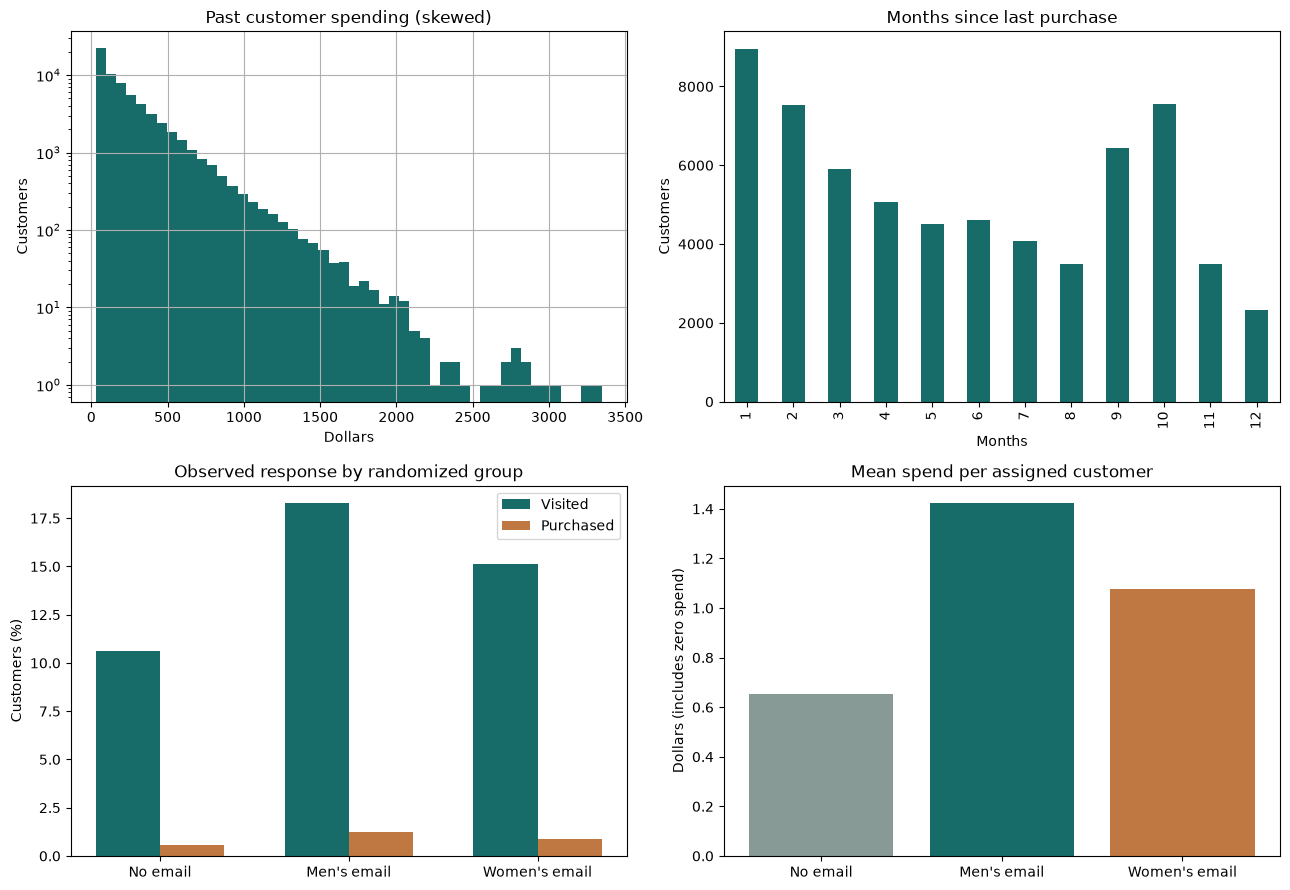

In [8]:
# Figure A: past spending is skewed; treatment-group outcomes show
# the large visit differences and the rarer purchase differences.
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
data.history.hist(bins=50, ax=axes[0, 0], color="#176b68")
axes[0, 0].set(title="Past customer spending (skewed)", xlabel="Dollars", ylabel="Customers")
axes[0, 0].set_yscale("log")
data.recency.value_counts().sort_index().plot.bar(ax=axes[0, 1], color="#176b68")
axes[0, 1].set(title="Months since last purchase", xlabel="Months", ylabel="Customers")

x = np.arange(len(ARMS)); width = 0.34
for offset, outcome, label, color in [(-width/2, "visit_rate", "Visited", "#176b68"),
                                      (width/2, "purchase_rate", "Purchased", "#c07842")]:
    vals = response.loc[ARMS, outcome].to_numpy() * 100
    axes[1, 0].bar(x + offset, vals, width, label=label, color=color)
axes[1, 0].set_xticks(x, ["No email", "Men's email", "Women's email"])
axes[1, 0].set(title="Observed response by randomized group", ylabel="Customers (%)")
axes[1, 0].legend()

spend_means = response.loc[ARMS, "mean_spend_per_customer"]
axes[1, 1].bar(["No email", "Men's email", "Women's email"], spend_means,
               color=["#879a96", "#176b68", "#c07842"])
axes[1, 1].set(title="Mean spend per assigned customer", ylabel="Dollars (includes zero spend)")
fig.tight_layout()
figure_dir = ROOT / "results/figures"
figure_dir.mkdir(parents=True, exist_ok=True)
fig.savefig(figure_dir / "eda.png", dpi=160, bbox_inches="tight")
plt.show()

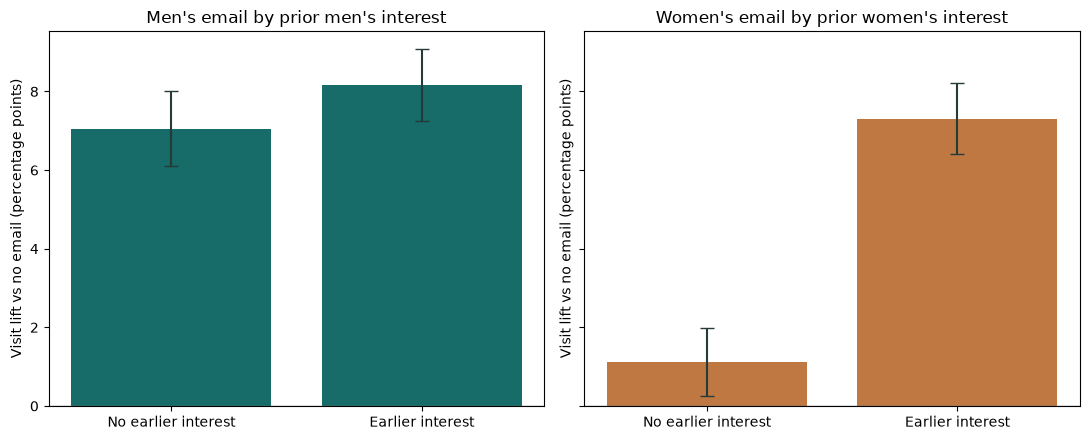

In [9]:
# Figure B: prior category interest is the most visible effect modifier
# in the simple randomized subgroup comparison.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5), sharey=True)
for ax, email, interest, title, color in [
    (axes[0], "Mens E-Mail", "mens", "Men's email by prior men's interest", "#176b68"),
    (axes[1], "Womens E-Mail", "womens", "Women's email by prior women's interest", "#c07842"),
]:
    table = interest_results.loc[interest_results.email == title.split("'s")[0] + "'s"]
    # Keep the displayed order: no prior interest, then interest present.
    table = table.set_index("prior_interest").reindex(["No prior interest flag", "Has prior interest flag"])
    y = table.visit_lift.to_numpy() * 100
    low = (table.visit_lift - table.ci95_low).to_numpy() * 100
    high = (table.ci95_high - table.visit_lift).to_numpy() * 100
    ax.bar(["No earlier interest", "Earlier interest"], y, color=color)
    ax.errorbar([0, 1], y, yerr=[low, high], fmt="none", color="#263b38", capsize=5)
    ax.axhline(0, color="gray", linewidth=1)
    ax.set_title(title)
    ax.set_ylabel("Visit lift vs no email (percentage points)")
fig.tight_layout()
fig.savefig(figure_dir / "eda_interest_effects.png", dpi=160, bbox_inches="tight")
plt.show()

In [10]:
# Keep the compact summary key names used by the dashboard.
group_summary = data.groupby("segment").agg(
    customers=("visit", "size"),
    visit_rate=("visit", "mean"),
    purchase_rate=("conversion", "mean"),
    average_spend=("spend", "mean"),
).reindex(ARMS)

summary = {
    "rows": len(data), "columns": len(data.columns),
    "missing_values": data.isna().sum().to_dict(),
    "identical_rows": int(data.duplicated().sum()),
    "purchases": int(data.conversion.sum()),
    "visit_rate": float(data.visit.mean()),
    "purchase_rate": float(data.conversion.mean()),
    "average_spend": float(data.spend.mean()),
    "groups": group_summary.reset_index().to_dict("records"),
    "source_sha256": hashlib.sha256(source_path.read_bytes()).hexdigest(),
    "decision": "Keep matching rows: no true customer ID proves they are duplicate people.",
}
detailed = {
    "baseline_balance": balance.to_dict("records"),
    "overall_email_differences": experimental_differences.to_dict("records"),
    "subgroup_visit_differences": subgroups.to_dict("records"),
    "prior_interest_interactions": interest_results.replace({np.nan: None}).to_dict("records"),
    "insights": [
        "All measured baseline pairwise SMDs are below 0.02, consistent with successful random assignment.",
        "Men's email has higher average visit lift than women's email in the full experiment.",
        "Women's email lift is much larger among customers with the prior women's-interest flag; treat this as an exploratory subgroup lead.",
        "Only 578 customers purchased, making purchase and spend estimates less precise than visit estimates.",
    ],
    "interpretation_note": "Subgroup analysis is exploratory and uses the full dataset; model performance is evaluated later on the held-out test split.",
}
save_result("eda.json", summary)
save_result("eda_detailed.json", detailed)
print("\nSaved baseline balance, response differences, subgroup tables and EDA figures under results/.")


Saved baseline balance, response differences, subgroup tables and EDA figures under results/.
